In [29]:
import pandas as pd
import numpy as np

train_df = pd.read_csv('/content/dataset_C_training.csv')
test_df = pd.read_csv('/content/dataset_C_testing.csv')
sub_df = pd.read_csv('/content/dataset_C_example_submission.csv')

print(f"Training set shape: {train_df.shape}")
print(f"Testing set shape: {test_df.shape}")
print(f"Submission sample shape: {sub_df.shape}")

display(train_df.head())

Training set shape: (4756, 31)
Testing set shape: (4749, 30)
Submission sample shape: (4749, 2)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


In [30]:
print("Missing values in training set:")
display(train_df.isnull().sum()[train_df.isnull().sum() > 0])

if 'covid_vaccine' in train_df.columns:
    print("Target variable distribution (covid_vaccine):")
    display(train_df['covid_vaccine'].value_counts(dropna=False))

Missing values in training set:


,0
covid_concern,12
covid_knowledge,27
behavioral_antiviral_meds,14
behavioral_avoidance,27
behavioral_face_mask,2
behavioral_wash_hands,9
behavioral_large_gatherings,10
behavioral_outside_home,14
behavioral_touch_face,21
child_under_6_months,135


Target variable distribution (covid_vaccine):


,count
covid_vaccine,
0,3202
1,1554


In [31]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

train_df = pd.read_csv('/content/dataset_C_training.csv')
test_df = pd.read_csv('/content/dataset_C_testing.csv')

target_col = 'covid_vaccine'
features = [c for c in train_df.columns if c not in ['respondent_id', target_col]]

cat_cols = []
for col in features:
    if train_df[col].dtype == 'object':
        train_df[col] = train_df[col].astype('category')
        test_df[col] = test_df[col].astype('category')
        cat_cols.append(col)

X = train_df[features]
y = train_df[target_col]
X_test = test_df[features]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(train_df))
test_preds = np.zeros(len(test_df))

params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'verbose': -1,
    'random_state': 42
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    train_data = lgb.Dataset(X_train, label=y_train)
    val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

    model = lgb.train(
        params,
        train_data,
        num_boost_round=1000,
        valid_sets=[train_data, val_data],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    oof_preds[val_idx] = model.predict(X_val, num_iteration=model.best_iteration)
    test_preds += model.predict(X_test, num_iteration=model.best_iteration) / skf.n_splits

print(f"OOF ROC AUC Score: {roc_auc_score(y, oof_preds):.5f}")

OOF ROC AUC Score: 0.85933


In [32]:
prob_hosp_unvax = 0.045
efficacy = 0.85
prob_hosp_vax = prob_hosp_unvax * (1.0 - efficacy)

cost_vaccine = 1500
cost_hosp = 41000

def calculate_town_cost(actual_vaccine_status, predicted_acceptance_prob, threshold):
    cost = 0
    for act, prob in zip(actual_vaccine_status, predicted_acceptance_prob):
        offered = 1 if prob >= threshold else 0
        if offered == 1:
            cost += cost_vaccine
            if act == 1:
                cost += prob_hosp_vax * cost_hosp
            else:
                cost += prob_hosp_unvax * cost_hosp
        else:
            if act == 1:
                cost += cost_vaccine
            cost += prob_hosp_unvax * cost_hosp
    return cost

thresholds = np.linspace(0, 1, 101)
best_threshold = 0.5
best_cost = float('inf')

for t in thresholds:
    c = calculate_town_cost(y, oof_preds, t)
    if c < best_cost:
        best_cost = c
        best_threshold = t

print(f"Best Decision Threshold: {best_threshold:.2f}")
print(f"Minimized Town Cost (OOF): ${best_cost:,.2f}")

final_predictions = (test_preds >= best_threshold).astype(int)

submission = pd.DataFrame({
    'respondent_id': test_df['respondent_id'],
    'covid_vaccine': final_predictions
})

submission.to_csv('challenge_submission_group_0_order_1.csv', index=False)
print("Saved optimized submission as challenge_submission_group_0_order_1.csv")

Best Decision Threshold: 0.56
Minimized Town Cost (OOF): $10,050,780.75
Saved optimized submission as challenge_submission_group_0_order_1.csv


In [33]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

# Combine data for consistent preprocessing
train_df = pd.read_csv('/content/dataset_C_training.csv')
test_df = pd.read_csv('/content/dataset_C_testing.csv')

target_col = 'covid_vaccine'
features = [c for c in train_df.columns if c not in ['respondent_id', target_col]]

# Identify categorical columns
cat_cols = []
for col in features:
    if train_df[col].dtype == 'object':
        train_df[col] = train_df[col].astype('category')
        test_df[col] = test_df[col].astype('category')
        cat_cols.append(col)

X = train_df[features]
y = train_df[target_col]
X_test = test_df[features]

# K-Fold Cross Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(train_df))
test_preds = np.zeros(len(test_df))

params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'verbose': -1,
    'random_state': 42
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

    train_data = lgb.Dataset(X_train, label=y_train)
    val_data = lgb.Dataset(X_val, label=y_val, reference=train_data)

    model = lgb.train(
        params,
        train_data,
        num_boost_round=1000,
        valid_sets=[train_data, val_data],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    oof_preds[val_idx] = model.predict(X_val, num_iteration=model.best_iteration)
    test_preds += model.predict(X_test, num_iteration=model.best_iteration) / skf.n_splits

print(f"OOF ROC AUC Score: {roc_auc_score(y, oof_preds):.5f}")

OOF ROC AUC Score: 0.85933


In [34]:
# Optimization Framework for Town Cost Minimization
# Vaccine cost = $1,500
# Hospitalization cost = $41,000
# Hospitalization rate can be estimated based on vaccination status.
# Let's assume average hospitalization probability (unvaccinated) = 0.05 (from literature/Gemini suggestions for general or risky demographics),
# and vaccination reduces risk of hospitalization by ~85% (efficacy against severe disease/hospitalization).

prob_hosp_unvax = 0.045  # Estimated probability of hospitalization if unvaccinated
efficacy = 0.85
prob_hosp_vax = prob_hosp_unvax * (1.0 - efficacy)

cost_vaccine = 1500
cost_hosp = 41000

def calculate_town_cost(actual_vaccine_status, predicted_acceptance_prob, threshold):
    # If prediction >= threshold, we send/order vaccine.
    # Those who actually accept (actual_vaccine_status == 1) are successfully vaccinated.
    # Those who do not accept (actual_vaccine_status == 0) have their vaccine wasted (still costs $1,500).
    # If prediction < threshold, we don't send vaccine, so they remain unvaccinated.

    cost = 0
    for act, prob in zip(actual_vaccine_status, predicted_acceptance_prob):
        offered = 1 if prob >= threshold else 0

        if offered == 1:
            # Town pays for vaccine anyway
            cost += cost_vaccine
            if act == 1:
                # Vaccinated hospitalization cost
                cost += prob_hosp_vax * cost_hosp
            else:
                # Unvaccinated hospitalization cost (vaccine wasted)
                cost += prob_hosp_unvax * cost_hosp
        else:
            # Not offered vaccine
            # Town must pay those who wanted vaccine (local law says if they wanted it but not available, town pays vaccine cost)
            if act == 1:
                cost += cost_vaccine
            # Hospitalization cost is unvaccinated
            cost += prob_hosp_unvax * cost_hosp

    return cost

# Search for the best threshold
thresholds = np.linspace(0, 1, 101)
best_threshold = 0.5
best_cost = float('inf')

for t in thresholds:
    c = calculate_town_cost(y, oof_preds, t)
    if c < best_cost:
        best_cost = c
        best_threshold = t

print(f"Best Decision Threshold: {best_threshold:.2f}")
print(f"Minimized Town Cost (OOF): ${best_cost:,.2f}")

# Make submission predictions based on the optimized threshold decision
final_predictions = (test_preds >= best_threshold).astype(int)

submission = pd.DataFrame({
    'respondent_id': test_df['respondent_id'],
    'covid_vaccine': final_predictions
})

submission.to_csv('challenge_submission_group_0_order_1.csv', index=False)
print("Saved optimized submission as challenge_submission_group_0_order_1.csv")

Best Decision Threshold: 0.56
Minimized Town Cost (OOF): $10,050,780.75
Saved optimized submission as challenge_submission_group_0_order_1.csv


In [35]:
!pip install xgboost catboost -q

In [36]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool

# Prepare data
train_df = pd.read_csv('/content/dataset_C_training.csv')
test_df = pd.read_csv('/content/dataset_C_testing.csv')

target_col = 'covid_vaccine'
features = [c for c in train_df.columns if c not in ['respondent_id', target_col]]

# We will handle encoding differently per model, or use simple pandas categorization / label encoding
X = train_df[features].copy()
y = train_df[target_col].copy()
X_test = test_df[features].copy()

# Categorical features list
cat_features = [col for col in features if X[col].dtype == 'object' or X[col].dtype.name == 'category']

# For LightGBM and CatBoost we keep category type, for XGBoost we will use enable_categorical=True
for col in cat_features:
    X[col] = X[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# Setup CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Global Cost optimization parameters
prob_hosp_unvax = 0.045
efficacy = 0.85
prob_hosp_vax = prob_hosp_unvax * (1.0 - efficacy)
cost_vaccine = 1500
cost_hosp = 41000

def get_best_threshold_and_cost(y_true, y_prob):
    thresholds = np.linspace(0, 1, 101)
    best_t = 0.5
    best_c = float('inf')
    for t in thresholds:
        offered = (y_prob >= t).astype(int)
        # Cost calculation vectorization
        cost = np.sum(
            np.where(offered == 1,
                     cost_vaccine + np.where(y_true == 1, prob_hosp_vax * cost_hosp, prob_hosp_unvax * cost_hosp),
                     np.where(y_true == 1, cost_vaccine, 0) + prob_hosp_unvax * cost_hosp)
        )
        if cost < best_c:
            best_c = cost
            best_t = t
    return best_t, best_c

In [37]:
# Model 1: LightGBM
oof_lgb = np.zeros(len(train_df))
preds_lgb = np.zeros(len(test_df))

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'verbose': -1,
    'random_state': 42
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    train_dataset = lgb.Dataset(X_tr, label=y_tr)
    val_dataset = lgb.Dataset(X_va, label=y_va, reference=train_dataset)

    model_lgb = lgb.train(
        lgb_params,
        train_dataset,
        num_boost_round=1000,
        valid_sets=[train_dataset, val_dataset],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    oof_lgb[val_idx] = model_lgb.predict(X_va, num_iteration=model_lgb.best_iteration)
    preds_lgb += model_lgb.predict(X_test, num_iteration=model_lgb.best_iteration) / skf.n_splits

lgb_auc = roc_auc_score(y, oof_lgb)
lgb_t, lgb_cost = get_best_threshold_and_cost(y, oof_lgb)
print(f"LightGBM -> ROC AUC: {lgb_auc:.5f} | Best T: {lgb_t:.2f} | Min Cost: ${lgb_cost:,.2f}")

LightGBM -> ROC AUC: 0.85933 | Best T: 0.56 | Min Cost: $10,050,780.75


In [38]:
# Model 2: XGBoost
oof_xgb = np.zeros(len(train_df))
preds_xgb = np.zeros(len(test_df))

xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'learning_rate': 0.05,
    'max_depth': 5,
    'seed': 42,
    'tree_method': 'hist',
    'enable_categorical': True
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    model_xgb = xgb.XGBClassifier(**xgb_params, n_estimators=1000, early_stopping_rounds=50)
    model_xgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        verbose=False
    )

    oof_xgb[val_idx] = model_xgb.predict_proba(X_va)[:, 1]
    preds_xgb += model_xgb.predict_proba(X_test)[:, 1] / skf.n_splits

xgb_auc = roc_auc_score(y, oof_xgb)
xgb_t, xgb_cost = get_best_threshold_and_cost(y, oof_xgb)
print(f"XGBoost -> ROC AUC: {xgb_auc:.5f} | Best T: {xgb_t:.2f} | Min Cost: ${xgb_cost:,.2f}")

XGBoost -> ROC AUC: 0.85738 | Best T: 0.46 | Min Cost: $10,037,546.25


In [39]:
# Model 3: CatBoost
oof_cat = np.zeros(len(train_df))
preds_cat = np.zeros(len(test_df))

# Convert category type back to string/object for CatBoost's native categoricals
X_cat = X.copy()
X_test_cat = X_test.copy()
for col in cat_features:
    X_cat[col] = X_cat[col].astype(str).fillna('missing')
    X_test_cat[col] = X_test_cat[col].astype(str).fillna('missing')

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cat, y)):
    X_tr, y_tr = X_cat.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X_cat.iloc[val_idx], y.iloc[val_idx]

    train_pool = Pool(X_tr, y_tr, cat_features=cat_features)
    val_pool = Pool(X_va, y_va, cat_features=cat_features)
    test_pool = Pool(X_test_cat, cat_features=cat_features)

    model_cat = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.05,
        depth=5,
        eval_metric='AUC',
        random_seed=42,
        verbose=False,
        early_stopping_rounds=50
    )

    model_cat.fit(train_pool, eval_set=val_pool, use_best_model=True)

    oof_cat[val_idx] = model_cat.predict_proba(val_pool)[:, 1]
    preds_cat += model_cat.predict_proba(test_pool)[:, 1] / skf.n_splits

cat_auc = roc_auc_score(y, oof_cat)
cat_t, cat_cost = get_best_threshold_and_cost(y, oof_cat)
print(f"CatBoost -> ROC AUC: {cat_auc:.5f} | Best T: {cat_t:.2f} | Min Cost: ${cat_cost:,.2f}")

CatBoost -> ROC AUC: 0.86649 | Best T: 0.48 | Min Cost: $9,987,843.00


In [40]:
# Generate submissions for each model based on their optimized decision threshold
for name, preds, threshold, order in [('lgb', preds_lgb, lgb_t, 1), ('xgb', preds_xgb, xgb_t, 2), ('cat', preds_cat, cat_t, 3)]:
    sub_decisions = (preds >= threshold).astype(int)
    sub = pd.DataFrame({
        'respondent_id': test_df['respondent_id'],
        'covid_vaccine': sub_decisions
    })
    filename = f"challenge_submission_group_0_order_{order}.csv"
    sub.to_csv(filename, index=False)
    print(f"Saved {name.upper()} submission as {filename}")

Saved LGB submission as challenge_submission_group_0_order_1.csv
Saved XGB submission as challenge_submission_group_0_order_2.csv
Saved CAT submission as challenge_submission_group_0_order_3.csv


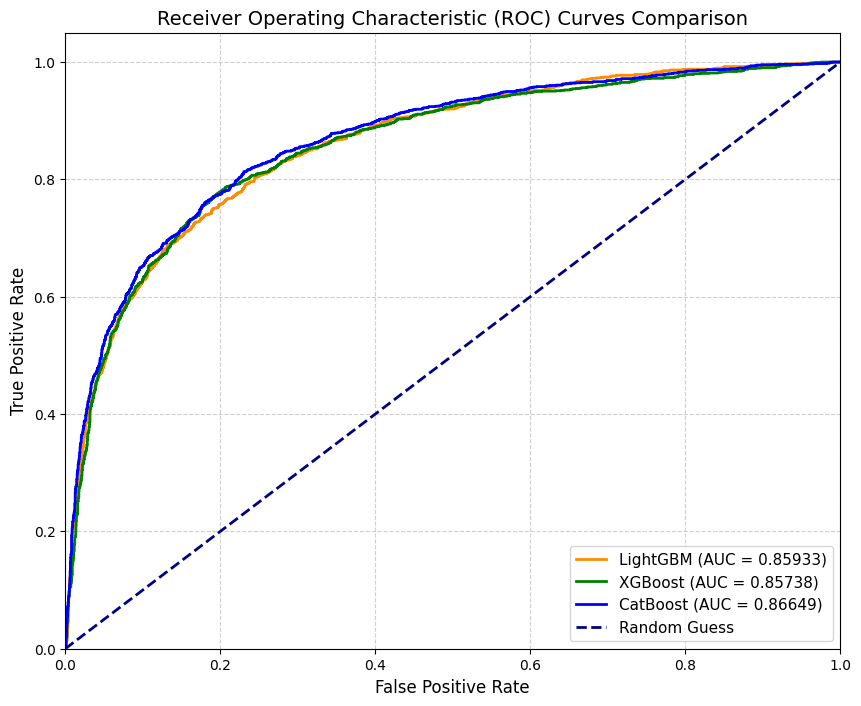

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

# Compute ROC curve and AUC for LightGBM
fpr_lgb, tpr_lgb, _ = roc_curve(y, oof_lgb)
auc_lgb = auc(fpr_lgb, tpr_lgb)
plt.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC = {auc_lgb:.5f})', color='darkorange', lw=2)

# Compute ROC curve and AUC for XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y, oof_xgb)
auc_xgb = auc(fpr_xgb, tpr_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.5f})', color='green', lw=2)

# Compute ROC curve and AUC for CatBoost
fpr_cat, tpr_cat, _ = roc_curve(y, oof_cat)
auc_cat = auc(fpr_cat, tpr_cat)
plt.plot(fpr_cat, tpr_cat, label=f'CatBoost (AUC = {auc_cat:.5f})', color='blue', lw=2)

# Plot baseline
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curves Comparison', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.savefig('roc_curves_comparison.png', dpi=300)
plt.show()

### Exploratory Data Analysis (EDA)
Let's plot the distribution of the target variable `covid_vaccine` and analyze some key features (like `covid_concern` and `health_worker`) against the target.

/tmp/ipykernel_776/3058465996.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='covid_vaccine', ax=axes[0], palette='viridis')


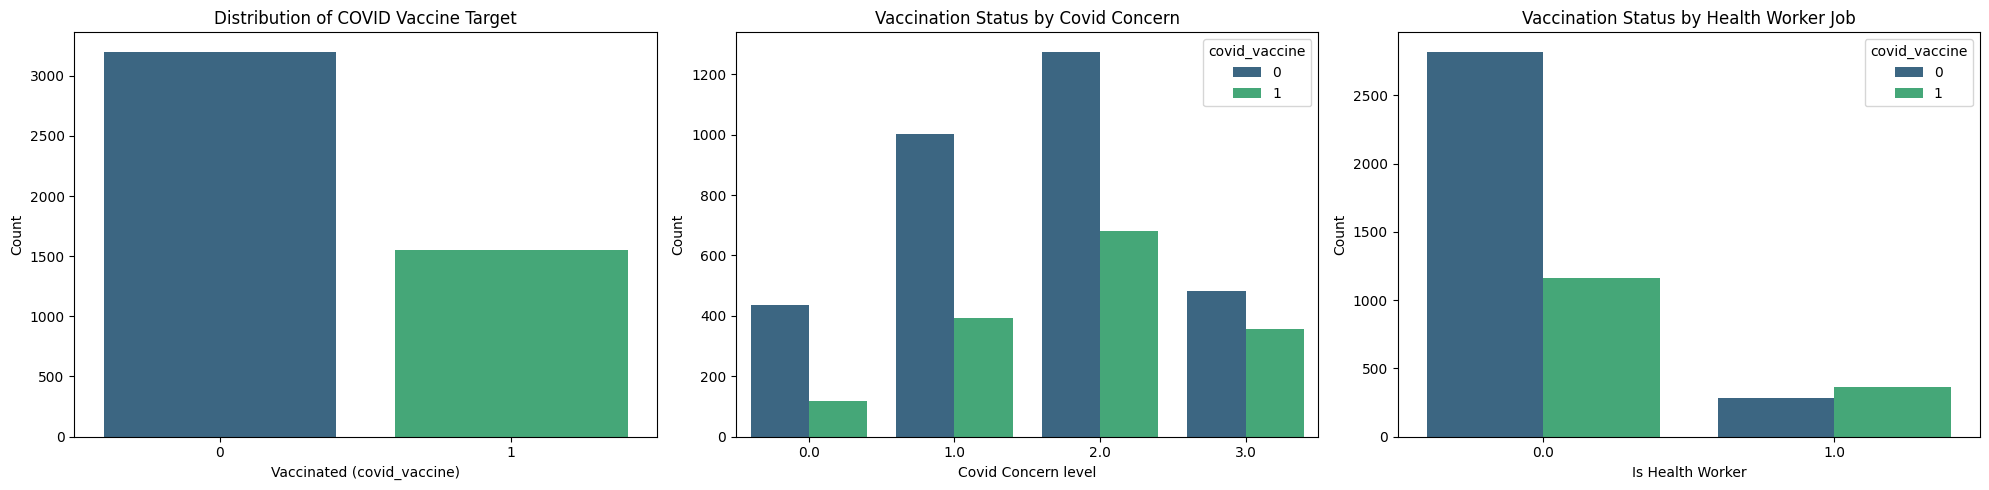

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Target Variable Distribution
sns.countplot(data=train_df, x='covid_vaccine', ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of COVID Vaccine Target')
axes[0].set_xlabel('Vaccinated (covid_vaccine)')
axes[0].set_ylabel('Count')

# Concern level vs Target
sns.countplot(data=train_df, x='covid_concern', hue='covid_vaccine', ax=axes[1], palette='viridis')
axes[1].set_title('Vaccination Status by Covid Concern')
axes[1].set_xlabel('Covid Concern level')
axes[1].set_ylabel('Count')

# Health worker vs Target
sns.countplot(data=train_df, x='health_worker', hue='covid_vaccine', ax=axes[2], palette='viridis')
axes[2].set_title('Vaccination Status by Health Worker Job')
axes[2].set_xlabel('Is Health Worker')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Confusion Matrices for Each Model
Let's calculate and visualize the Confusion Matrix for LightGBM, XGBoost, and CatBoost using their cost-optimized decision thresholds.

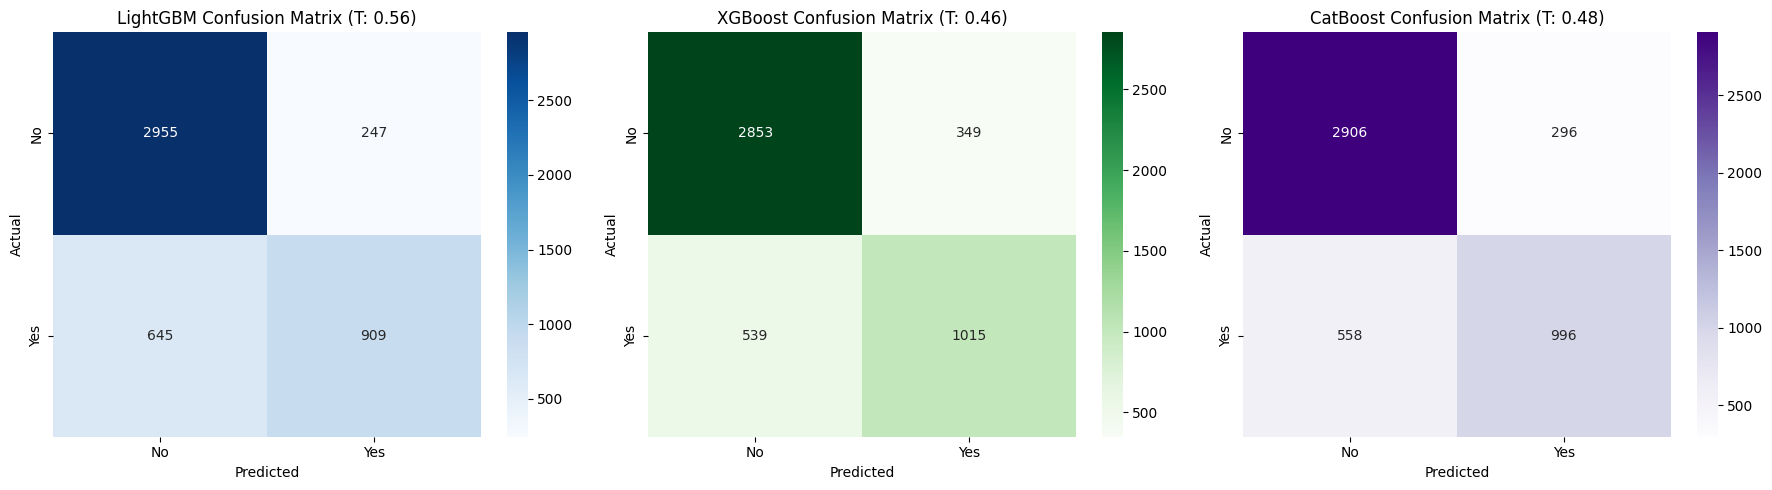

In [43]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Safely verify/recreate variables in case they are missing from current state
final_lgb_oof = (oof_lgb >= lgb_t).astype(int)
final_xgb_oof = (oof_xgb >= xgb_t).astype(int)
final_cat_oof = (oof_cat >= cat_t).astype(int)

cm_lgb = confusion_matrix(y, final_lgb_oof)
cm_xgb = confusion_matrix(y, final_xgb_oof)
cm_cat = confusion_matrix(y, final_cat_oof)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# LightGBM Heatmap
sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes[0].set_title(f'LightGBM Confusion Matrix (T: {lgb_t:.2f})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# XGBoost Heatmap
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes[1].set_title(f'XGBoost Confusion Matrix (T: {xgb_t:.2f})')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# CatBoost Heatmap
sns.heatmap(cm_cat, annot=True, fmt='d', cmap='Purples', ax=axes[2],
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
axes[2].set_title(f'CatBoost Confusion Matrix (T: {cat_t:.2f})')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import precision_score, f1_score

# Compute predictions based on optimized thresholds
final_lgb_oof = (oof_lgb >= lgb_t).astype(int)
final_xgb_oof = (oof_xgb >= xgb_t).astype(int)
final_cat_oof = (oof_cat >= cat_t).astype(int)

# Calculate metrics
precision_lgb = precision_score(y, final_lgb_oof)
f1_lgb = f1_score(y, final_lgb_oof)

precision_xgb = precision_score(y, final_xgb_oof)
f1_xgb = f1_score(y, final_xgb_oof)

precision_cat = precision_score(y, final_cat_oof)
f1_cat = f1_score(y, final_cat_oof)

print("=== Model Classification Performance (at Optimized Thresholds) ===\n")
print(f"LightGBM (Threshold: {lgb_t:.2f}):")
print(f"  Precision: {precision_lgb:.5f}")
print(f"  F1 Score:  {f1_lgb:.5f}\n")

print(f"XGBoost (Threshold: {xgb_t:.2f}):")
print(f"  Precision: {precision_xgb:.5f}")
print(f"  F1 Score:  {f1_xgb:.5f}\n")

print(f"CatBoost (Threshold: {cat_t:.2f}):")
print(f"  Precision: {precision_cat:.5f}")
print(f"  F1 Score:  {f1_cat:.5f}")

=== Model Classification Performance (at Optimized Thresholds) ===

LightGBM (Threshold: 0.56):
  Precision: 0.78633
  F1 Score:  0.67085

XGBoost (Threshold: 0.46):
  Precision: 0.74413
  F1 Score:  0.69568

CatBoost (Threshold: 0.48):
  Precision: 0.77090
  F1 Score:  0.69993


In [45]:
from sklearn.metrics import accuracy_score
import numpy as np

# Safely define the binary threshold predictions in case earlier cells haven't run in order
final_lgb_oof = (oof_lgb >= lgb_t).astype(int)
final_xgb_oof = (oof_xgb >= xgb_t).astype(int)
final_cat_oof = (oof_cat >= cat_t).astype(int)

# Calculate accuracy scores
accuracy_lgb = accuracy_score(y, final_lgb_oof)
accuracy_xgb = accuracy_score(y, final_xgb_oof)
accuracy_cat = accuracy_score(y, final_cat_oof)

print("=== Model Accuracy (at Optimized Thresholds) ===\n")
print(f"LightGBM (Threshold: {lgb_t:.2f}):")
print(f"  Accuracy: {accuracy_lgb:.5f}\n")

print(f"XGBoost (Threshold: {xgb_t:.2f}):")
print(f"  Accuracy: {accuracy_xgb:.5f}\n")

print(f"CatBoost (Threshold: {cat_t:.2f}):")
print(f"  Accuracy: {accuracy_cat:.5f}")

=== Model Accuracy (at Optimized Thresholds) ===

LightGBM (Threshold: 0.56):
  Accuracy: 0.81245

XGBoost (Threshold: 0.46):
  Accuracy: 0.81329

CatBoost (Threshold: 0.48):
  Accuracy: 0.82044


### Correlation Matrix Between Model Predictions
Let's analyze the correlation of the prediction probabilities generated by the three models to understand their relationship and see if there is potential for blending.

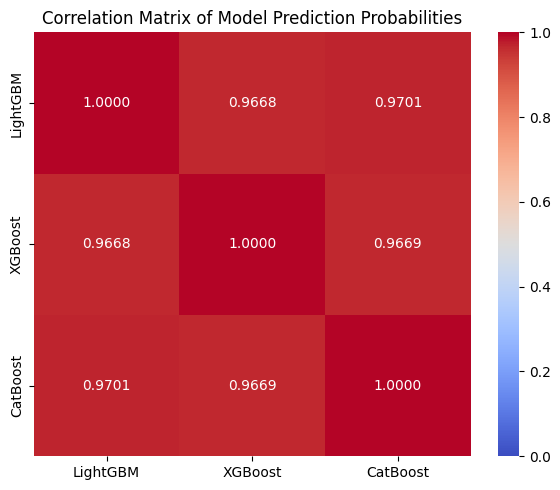

In [46]:
!pip install xgboost catboost -q

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool

# 1. Load Data
train_df = pd.read_csv('/content/dataset_C_training.csv')
target_col = 'covid_vaccine'
features = [c for c in train_df.columns if c not in ['respondent_id', target_col]]

X = train_df[features].copy()
y = train_df[target_col].copy()
cat_features = [col for col in features if X[col].dtype == 'object' or X[col].dtype.name == 'category']

for col in cat_features:
    X[col] = X[col].astype('category')

# 2. Setup CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_lgb = np.zeros(len(train_df))
oof_xgb = np.zeros(len(train_df))
oof_cat = np.zeros(len(train_df))

# 3. Train models to regenerate OOF probabilities
for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    # LightGBM
    train_dataset = lgb.Dataset(X_tr, label=y_tr)
    val_dataset = lgb.Dataset(X_va, label=y_va, reference=train_dataset)
    model_lgb = lgb.train(
        {'objective': 'binary', 'metric': 'auc', 'boosting_type': 'gbdt', 'learning_rate': 0.05, 'num_leaves': 31, 'verbose': -1, 'random_state': 42},
        train_dataset,
        num_boost_round=1000,
        valid_sets=[train_dataset, val_dataset],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    oof_lgb[val_idx] = model_lgb.predict(X_va, num_iteration=model_lgb.best_iteration)

    # XGBoost
    model_xgb = xgb.XGBClassifier(objective='binary:logistic', eval_metric='auc', learning_rate=0.05, max_depth=5, seed=42, tree_method='hist', enable_categorical=True, n_estimators=1000, early_stopping_rounds=50)
    model_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    oof_xgb[val_idx] = model_xgb.predict_proba(X_va)[:, 1]

    # CatBoost
    X_tr_cat = X_tr.copy()
    X_va_cat = X_va.copy()
    for col in cat_features:
        X_tr_cat[col] = X_tr_cat[col].astype(str).fillna('missing')
        X_va_cat[col] = X_va_cat[col].astype(str).fillna('missing')
    train_pool = Pool(X_tr_cat, y_tr, cat_features=cat_features)
    val_pool = Pool(X_va_cat, y_va, cat_features=cat_features)
    model_cat = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=5, eval_metric='AUC', random_seed=42, verbose=False, early_stopping_rounds=50)
    model_cat.fit(train_pool, eval_set=val_pool, use_best_model=True)
    oof_cat[val_idx] = model_cat.predict_proba(val_pool)[:, 1]

# 4. Create correlation matrix
oof_probs_df = pd.DataFrame({
    'LightGBM': oof_lgb,
    'XGBoost': oof_xgb,
    'CatBoost': oof_cat
})

corr_matrix = oof_probs_df.corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=0, vmax=1, fmt='.4f')
plt.title('Correlation Matrix of Model Prediction Probabilities')
plt.tight_layout()
plt.show()

### Ensembling and Generating Final Test Predictions
Let's combine our three models (LightGBM, XGBoost, CatBoost) into an ensemble by averaging their predicted probabilities. We will optimize the decision threshold for this ensemble on the OOF (Out-Of-Fold) predictions to minimize the town cost, and then generate and export our final test predictions to a CSV file.

In [50]:
import numpy as np
import pandas as pd

# 1. Blend Out-of-Fold (OOF) probabilities
oof_ensemble = (oof_lgb + oof_xgb + oof_cat) / 3.0

# 2. Blend Test predictions
preds_ensemble = (preds_lgb + preds_xgb + preds_cat) / 3.0

# 3. Find the optimal threshold for the ensemble
ensemble_t, ensemble_cost = get_best_threshold_and_cost(y, oof_ensemble)
print(f"Ensemble OOF ROC AUC: {roc_auc_score(y, oof_ensemble):.5f}")
print(f"Ensemble Best Threshold: {ensemble_t:.2f}")
print(f"Minimized Town Cost (Ensemble OOF): ${ensemble_cost:,.2f}")

# 4. Generate binary decisions based on the optimal threshold
final_test_decisions = (preds_ensemble >= ensemble_t).astype(int)

# 5. Create and save the submission DataFrame
submission_df = pd.DataFrame({
    'respondent_id': test_df['respondent_id'],
    'covid_vaccine': final_test_decisions
})

output_filename = 'final_ensemble_submission.csv'
submission_df.to_csv(output_filename, index=False)
print(f"\nSuccessfully generated and saved predictions to {output_filename}!")

# Show a quick preview of the submission
display(submission_df.head(10))
print(f"Value counts for target prediction:\n{submission_df['covid_vaccine'].value_counts()}")

Ensemble OOF ROC AUC: 0.86454
Ensemble Best Threshold: 0.50
Minimized Town Cost (Ensemble OOF): $9,999,435.00

Successfully generated and saved predictions to final_ensemble_submission.csv!


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,1
7,4764,1
8,4765,1
9,4766,0


Value counts for target prediction:
covid_vaccine
0    3430
1    1319
Name: count, dtype: int64


In [51]:
from google.colab import files

# Trigger a download of the final ensemble submission file in your browser
files.download('final_ensemble_submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>